# **Solar-Flare Forecasting with Machine Learning**

Overview

This project investigates machine-learning approaches for forecasting solar flares using active-region observations from the SDO/HMI SHARP dataset.

The analysis focuses on data preprocessing, class imbalance, active-region-based data splitting to reduce information leakage, feature engineering, and comparison of tree-based classification models.

**Course:** Astronomy 101, Equinox — The Astronomy Club of IIT Guwahati

**Year:** 2026

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit

pd.set_option("display.max_columns", 20)
sns.set_style("whitegrid")


# **1. Dataset**

The project uses SDO/HMI SHARP active-region observations provided as part of the Astronomy 101 course conducted by Equinox, The Astronomy Club of IIT Guwahati.

The dataset contains magnetic-field and active-region parameters used to investigate whether machine-learning models can distinguish flare-producing from non-flaring observations.

Data availability

The datasets used in this analysis were provided by the Equinox Astronomy 101 course team and are not redistributed in this repository.

In [ ]:
df = pd.read_csv('training_data_M5_24.csv')
print("Raw shape:", df.shape)
df.head()

Raw shape: (200842, 13)


,Flare,DATE__OBS,NOAA_AR,HARPNUM,USFLUX,TOTUSJH,TOTUSJZ,MEANALP,R_VALUE,TOTPOT,SAVNCPP,AREA_ACR,ABSNJZH
0,N,2023-01-03 18:36:00,13177,8923,-0.877771,-0.851649,-0.841043,-0.445579,0.372630,-0.892655,-0.869557,-0.695751,-0.878711
1,N,2023-01-03 18:48:00,13177,8923,-0.875756,-0.847173,-0.835644,-0.446498,0.350569,-0.892883,-0.885357,-0.694607,-0.881184
2,N,2023-01-03 19:00:00,13177,8923,-0.875219,-0.844854,-0.831772,-0.449348,0.367115,-0.892317,-0.882771,-0.695381,-0.892749
3,N,2023-01-03 19:12:00,13177,8923,-0.871942,-0.838273,-0.821357,-0.449396,0.341262,-0.891861,-0.896272,-0.695834,-0.891898
4,N,2023-01-03 19:24:00,13177,8923,-0.868639,-0.833376,-0.813119,-0.446525,0.326784,-0.894040,-0.875498,-0.698612,-0.880152


In [ ]:
df.dtypes

,0
Flare,object
DATE__OBS,object
NOAA_AR,int64
HARPNUM,int64
USFLUX,float64
TOTUSJH,float64
TOTUSJZ,float64
MEANALP,float64
R_VALUE,float64
TOTPOT,float64


# **2. Initial Data Exploration**

The first stage of the analysis examines the structure of the dataset, available variables, data types, and flare-label distribution.

## Dataset Shape and Data Type


In [ ]:
print("Shape:", df.shape)
print()
print("Data types:")
print(df.dtypes)

Shape: (200842, 13)

Data types:
Flare         object
DATE__OBS     object
NOAA_AR        int64
HARPNUM        int64
USFLUX       float64
TOTUSJH      float64
TOTUSJZ      float64
MEANALP      float64
R_VALUE      float64
TOTPOT       float64
SAVNCPP      float64
AREA_ACR     float64
ABSNJZH      float64
dtype: object


## Missing values

In [ ]:
print("Missing values per column:")
print(df.isna().sum())
print("Total missing values:", df.isna().sum().sum())

Missing values per column:
Flare        0
DATE__OBS    0
NOAA_AR      0
HARPNUM      0
USFLUX       0
TOTUSJH      0
TOTUSJZ      0
MEANALP      0
R_VALUE      0
TOTPOT       0
SAVNCPP      0
AREA_ACR     0
ABSNJZH      0
dtype: int64
Total missing values: 0


There are no missing values in the observation.

## Duplicate Observation

In [ ]:
feats = ['USFLUX','TOTUSJH','TOTUSJZ','MEANALP','R_VALUE','TOTPOT','SAVNCPP','AREA_ACR','ABSNJZH']
print("Exact full-row duplicates:", df.duplicated().sum())
print("Duplicate rows on the 9 feature columns only:", df.duplicated(subset=feats).sum())

Exact full-row duplicates: 0
Duplicate rows on the 9 feature columns only: 65807


## Target Distribution

In [ ]:
df['Flare'].value_counts()

,count
Flare,
N,123840
padding,65808
P,11194


## Feature distribution


Plotting distributions of numerical features...


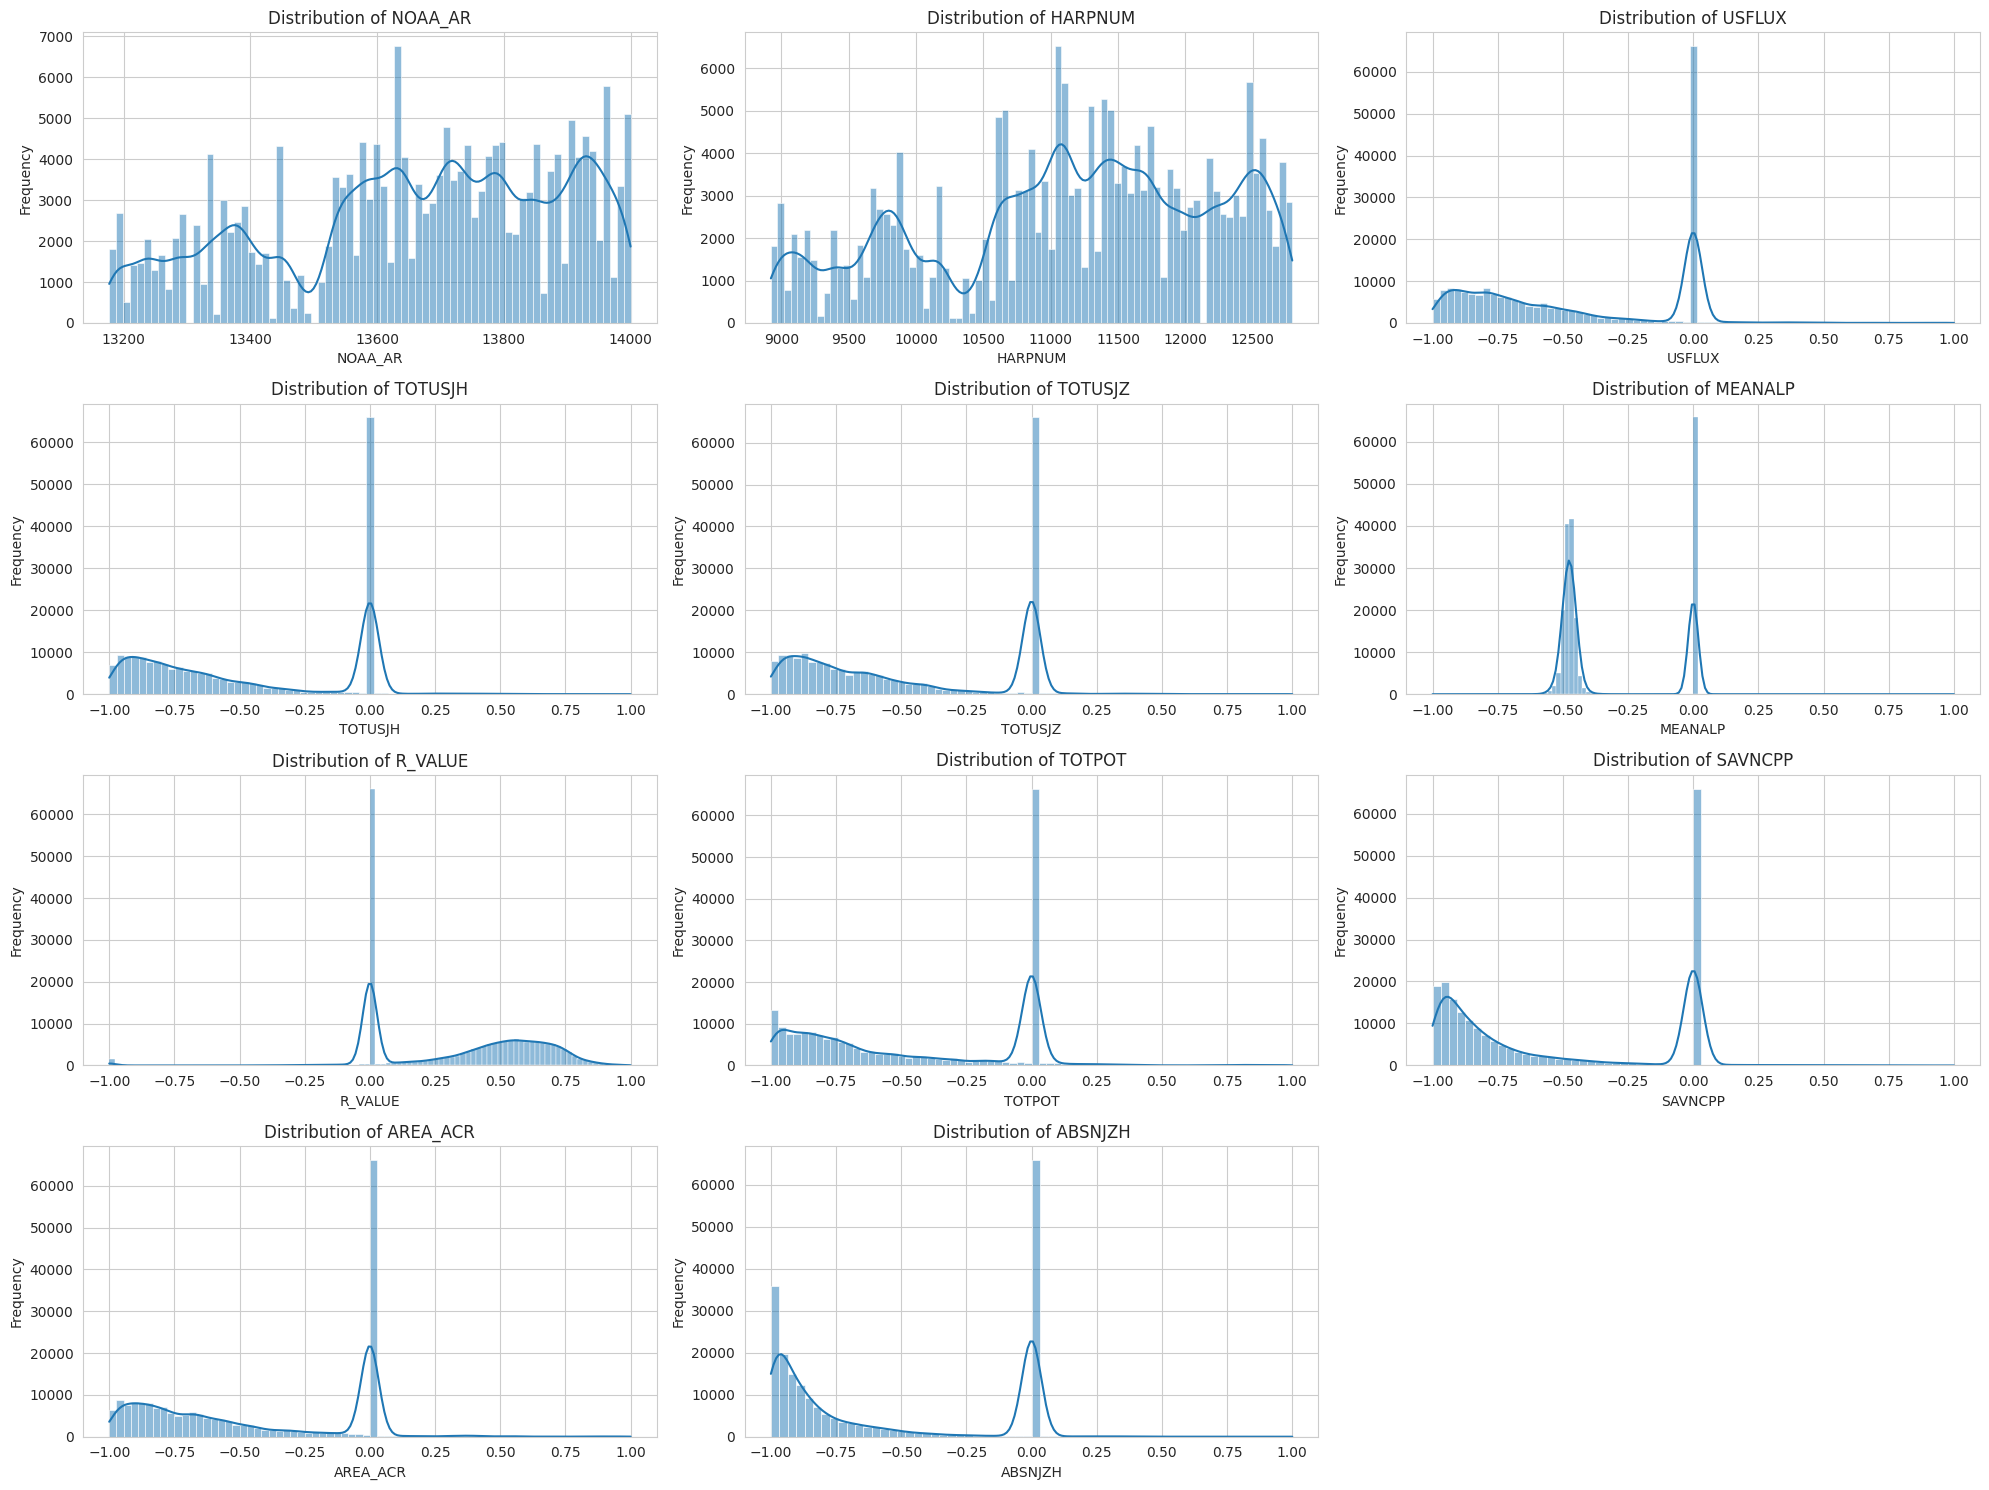

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

if df is not None:
    # Separating numerical and categorical features
    numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()

    print("Plotting distributions of numerical features...")
    plt.figure(figsize=(20, 15))
    for i, col in enumerate(numerical_cols):
        plt.subplot(4, 3, i + 1) # Adjust subplot grid as needed, assuming up to 12 numerical features for now
        sns.histplot(df[col], kde=True)
        plt.title(f'Distribution of {col}')
        plt.xlabel(col)
        plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()
else:
    print("DataFrame is not loaded, cannot plot feature distributions.")

#### NOAA and HARPNUM are assigned IDs for each spot on sun. Thus the distribution of them doesnt have a proper function and it is random.
####**USFLUX**: Its the total unsigned magnetic flux. It has a left tailed skew plot, which tells us that most solar regions do not have strong magnetic field. Thus highly magnetized regions are extremely rare.
####**TOTUSJH**: It shows how twisted the magnetic field is. And again we can see a similar plot as before, this means only a small solar region has twisted magnetic field, these are the regions which causes solar flare.
####**TOTUSJZ**: This is accountable to tell about the vertical current. We again get similar results, which means only a small solar region has electric current.
####**MEANALP**: This tells us magnetic twist parameter. It has two peaks which is a bimodal distribution. From this we know the active regions have two types of TOTUSJH with average magnetic twist.
####**R_VALUE**: It measures how much opposite flux is packed together. Since it has kind of right tailed skew plot, we can infer that most regions have no opposite polarity and only a small portion of has very high opposite polarity.
####**TOTPOT**: This tells us abbout total stored magnetic energy available for sudden release. Thank god the plot for this one also tells theres veryy little energy stored in most of the regions. This energy is accountable for solar flare and CME. Thus we know most active regions don;t produce solar flares, only very little have stored max energy.
####**SAVNCCP**: This tells electric current per polarity. This is also skewed with same interpretetion.
####**AREA_ACR & ABSNJZH**:these both also interpret the same thing.


####This tells us that most of the time sun spends being quite, only a small portion of sun produces solar flare.

## Correlation with Target

In [ ]:
df['target_naive'] = (df['Flare'] == 'P').astype(int)  # naive encoding, padding rows land in class 0
corr_raw = df[feats + ['target_naive']].corr()['target_naive'].drop('target_naive').sort_values(ascending=False)
corr_raw

,target_naive
R_VALUE,0.268490
TOTPOT,0.046453
TOTUSJH,0.013292
TOTUSJZ,-0.011270
USFLUX,-0.016512
AREA_ACR,-0.020010
SAVNCPP,-0.048671
ABSNJZH,-0.060669
MEANALP,-0.170193


In [ ]:
pad = df[df['Flare']=='padding']
print(pad[['USFLUX','TOTUSJH','TOTUSJZ','MEANALP','R_VALUE','TOTPOT','SAVNCPP','AREA_ACR','ABSNJZH']].describe().loc[['mean','std','min','max']])
print()
print("Distinct HARPNUM values with padding rows:", pad['HARPNUM'].nunique(), "out of", df['HARPNUM'].nunique())
print("Example DATE__OBS format in padding rows:", pad['DATE__OBS'].iloc[0])
print("Example DATE__OBS format in real rows:    ", df[df['Flare']!='padding']['DATE__OBS'].iloc[0])

      USFLUX  TOTUSJH  TOTUSJZ  MEANALP  R_VALUE  TOTPOT  SAVNCPP  AREA_ACR  \
mean     0.0      0.0      0.0      0.0      0.0     0.0      0.0       0.0   
std      0.0      0.0      0.0      0.0      0.0     0.0      0.0       0.0   
min      0.0      0.0      0.0      0.0      0.0     0.0      0.0       0.0   
max      0.0      0.0      0.0      0.0      0.0     0.0      0.0       0.0   

      ABSNJZH  
mean      0.0  
std       0.0  
min       0.0  
max       0.0  

Distinct HARPNUM values with padding rows: 274 out of 275
Example DATE__OBS format in padding rows: 2023-01-04T06:00:00.000Z
Example DATE__OBS format in real rows:     2023-01-03 18:36:00


During data exploration, I found that every row labeled padding had all nine magnetic-field features exactly equal to 0.0, with zero variance across every feature. These rows also used a different timestamp format from the real observations and appeared across almost every HARPNUM. This strongly suggests that they are artificial placeholder rows added during preprocessing rather than genuine SDO measurements. Since they contain no physical information and would bias the model toward the majority class, I removed all padding rows before training the classifier.

In [ ]:
df_real = df[df['Flare'] != 'padding'].copy()
print("Shape after removing padding rows:", df_real.shape)
df_real['target'] = (df_real['Flare'] == 'P').astype(int)
df_real['DATE__OBS'] = pd.to_datetime(df_real['DATE__OBS'])
df_real = df_real.sort_values(['HARPNUM','DATE__OBS']).reset_index(drop=True)
df_real['target'].value_counts()

Shape after removing padding rows: (135034, 14)


,count
target,
0,123840
1,11194


### Relationships Between Features and Target Variable (`Flare`)


Plotting relationships between numerical features and 'Flare'


/tmp/ipykernel_1348/1839567961.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Flare', y=col, data=df, palette='viridis')
/tmp/ipykernel_1348/1839567961.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Flare', y=col, data=df, palette='viridis')
/tmp/ipykernel_1348/1839567961.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Flare', y=col, data=df, palette='viridis')
/tmp/ipykernel_1348/1839567961.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x`

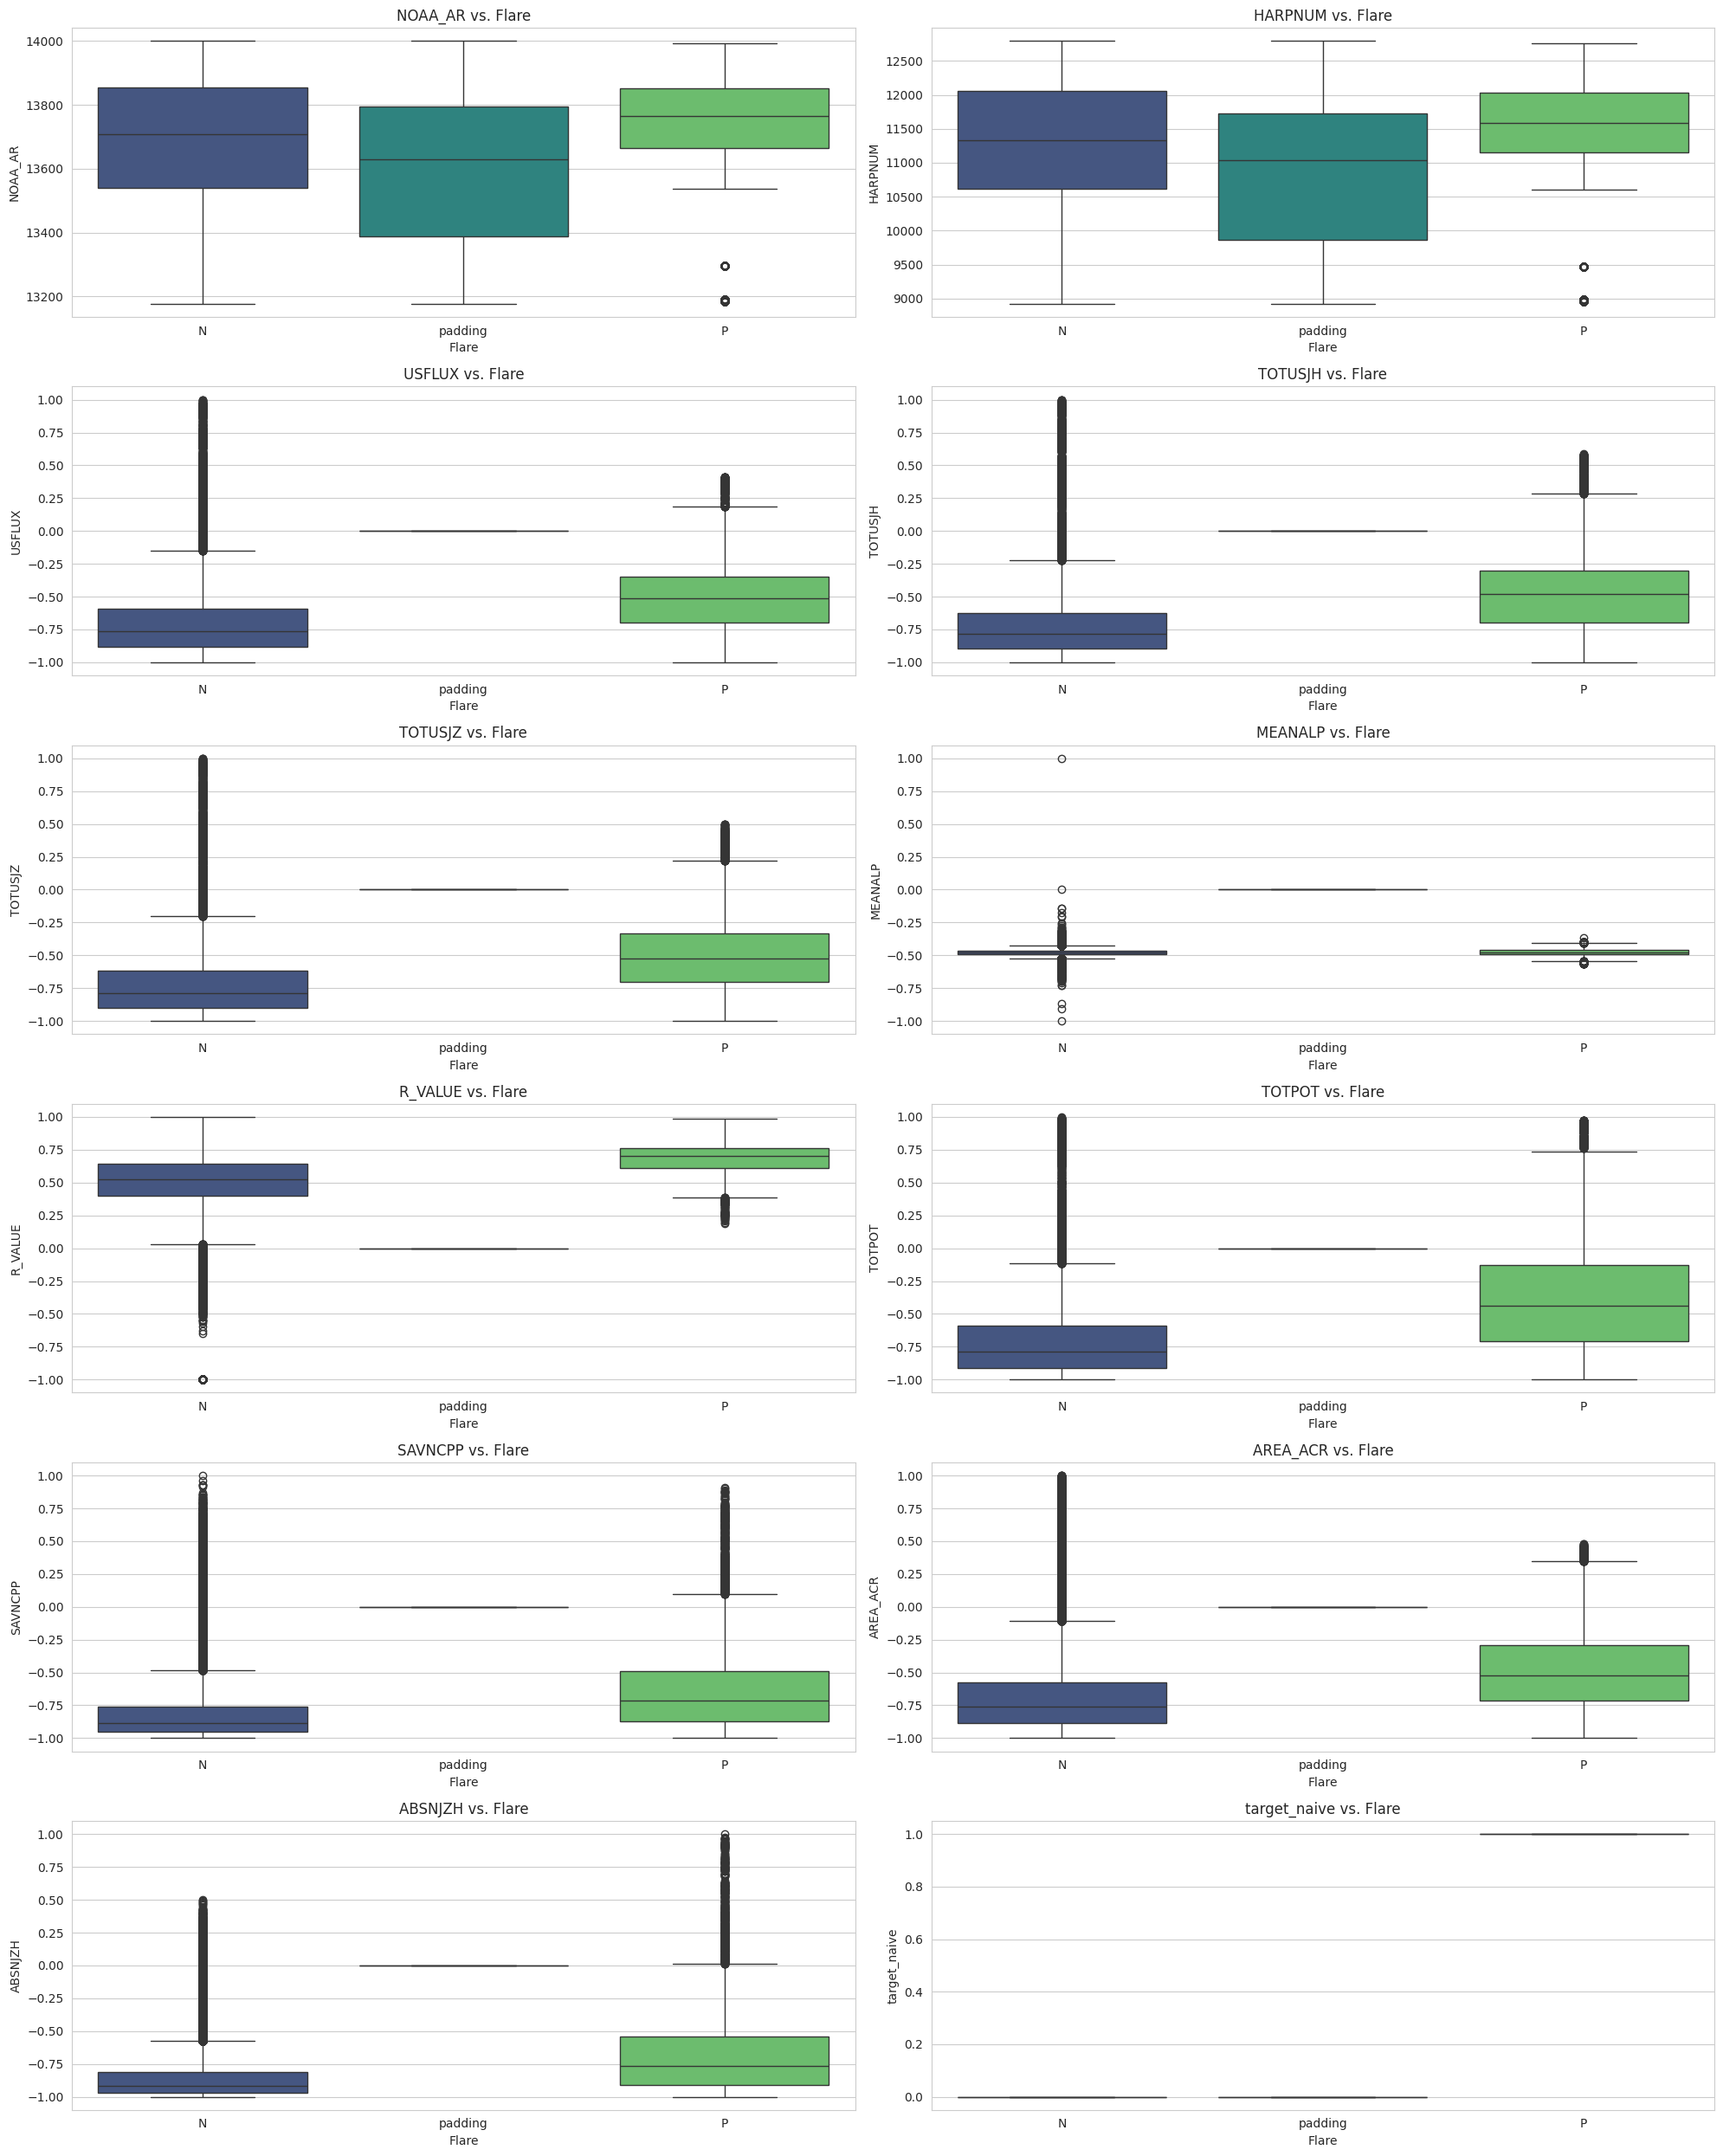

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

if df is not None:
    numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()

    print("Plotting relationships between numerical features and 'Flare'")
    plt.figure(figsize=(20, 25))
    for i, col in enumerate(numerical_cols):
        plt.subplot(6, 2, i + 1)
        sns.boxplot(x='Flare', y=col, data=df, palette='viridis')
        plt.title(f'{col} vs. Flare')
        plt.xlabel('Flare')
        plt.ylabel(col)
    plt.tight_layout()
    plt.show()
else:
    print("DataFrame is not loaded, can't plot the feature-target relationships.")

#### In **NOAA_AR** and **HARPNUM**, the plots do not show any meaningful pattern because these columns are only identification numbers for solar active regions and do not represent physical properties.

#### **USFLUX**: The P region has slightly higher values than the N region, indicating that flare-producing active regions generally have higher total magnetic flux.

#### **TOTUSJH**: The P region has higher values, indicating that flare-producing regions have greater current helicity (more twisted magnetic fields).

#### **TOTUSJZ**: The P region has slightly higher values, suggesting that flare-producing regions tend to have stronger vertical electric currents.

#### **MEANALP**: There is considerable overlap between the N and P regions, indicating that the mean magnetic twist alone is not a strong predictor of solar flares.

#### **R_VALUE**: The P region has noticeably higher values than the N region, showing that flare-producing regions have more magnetic flux concentrated near the polarity inversion line, making them more likely to undergo magnetic reconnection.

#### **TOTPOT**: The P region generally has higher values, indicating that flare-producing regions store more free magnetic energy available for sudden release during a flare.

#### **SAVNCPP**: The P region tends to have higher values, suggesting that flare-producing regions have stronger net electric currents.

#### **AREA_ACR**: The P region has slightly larger values on average, indicating that larger active regions are somewhat more likely to produce flares, although there is significant overlap.

#### **ABSNJZH**: The P region generally has higher values, showing that flare-producing regions possess greater absolute current helicity, which is associated with more stressed and twisted magnetic fields.

### Feature Correlation Analysis


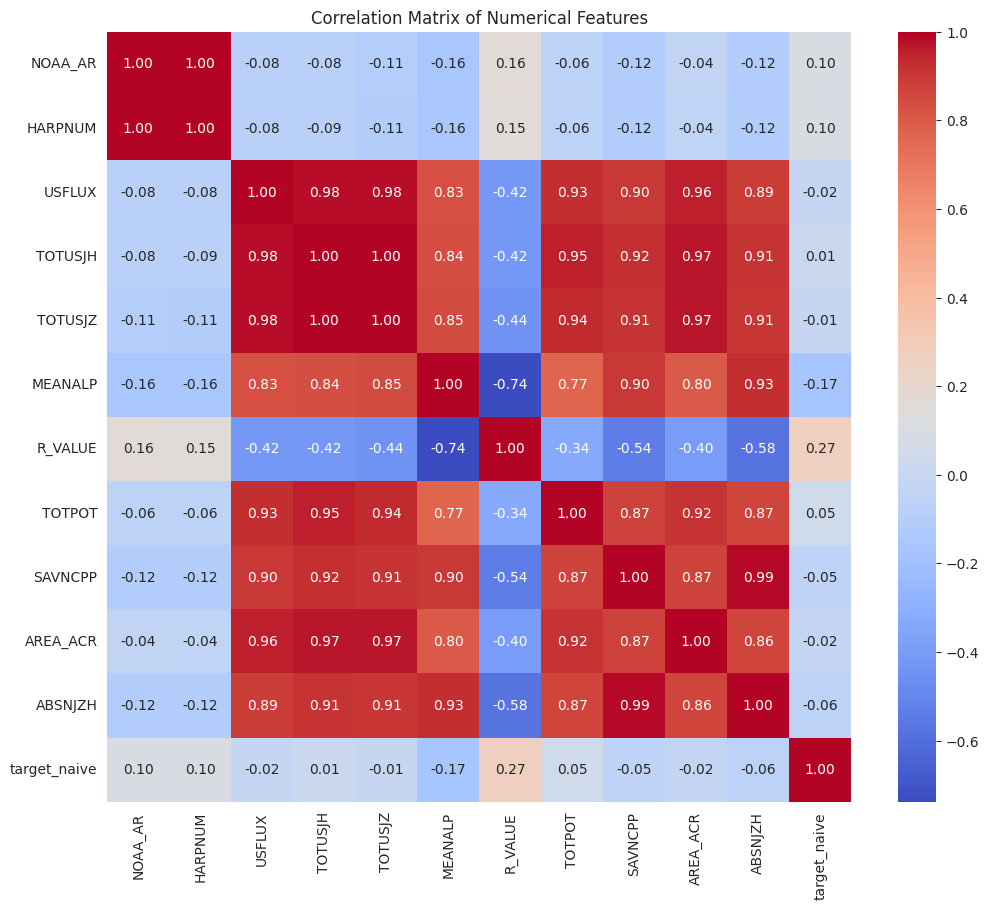

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

if df is not None:
    numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()

    correlation_matrix = df[numerical_cols].corr()

    plt.figure(figsize=(12, 10))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
    plt.title('Correlation Matrix of Numerical Features')
    plt.show()
else:
    print("DataFrame is not loaded")

# **3. Data Cleaning and Class Imbalance**

The dataset contains observations labelled padding in addition to the two physical classes, non-flaring (N) and flaring (P).

Inspection of the padding observations shows that the magnetic-field features are identically zero and that their timestamps follow a different format from the physical observations. These rows are therefore excluded from the machine-learning analysis.

After removing the padding observations, the dataset contains 135,034 observations: 123,840 non-flaring (N) and 11,194 flaring (P) observations, corresponding to an approximately 11:1 class imbalance.

Because multiple observations can originate from the same solar active region, observations are grouped by HARP NUM when constructing the train-validation split to prevent active-region information from leaking between the two sets.

### Identifying Padding Observations

In [ ]:
pad = df[df['Flare']=='padding']
print(pad[feats].describe().loc[['mean','std','min','max']])
print()
print("Distinct HARPNUM values with padding rows:", pad['HARPNUM'].nunique(), "out of", df['HARPNUM'].nunique())
print("Example DATE__OBS format in padding rows:", pad['DATE__OBS'].iloc[0])
print("Example DATE__OBS format in real rows:    ", df[df['Flare']!='padding']['DATE__OBS'].iloc[0])

      USFLUX  TOTUSJH  TOTUSJZ  MEANALP  R_VALUE  TOTPOT  SAVNCPP  AREA_ACR  \
mean     0.0      0.0      0.0      0.0      0.0     0.0      0.0       0.0   
std      0.0      0.0      0.0      0.0      0.0     0.0      0.0       0.0   
min      0.0      0.0      0.0      0.0      0.0     0.0      0.0       0.0   
max      0.0      0.0      0.0      0.0      0.0     0.0      0.0       0.0   

      ABSNJZH  
mean      0.0  
std       0.0  
min       0.0  
max       0.0  

Distinct HARPNUM values with padding rows: 274 out of 275
Example DATE__OBS format in padding rows: 2023-01-04T06:00:00.000Z
Example DATE__OBS format in real rows:     2023-01-03 18:36:00


### Removing Padding Observations

In [ ]:
# Remove artificial padding observations
df_real = df[df["Flare"] != "padding"].copy()

# Encode the flare label as a binary target
df_real["target"] = (df_real["Flare"] == "P").astype(int)

In [ ]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, val_idx = next(gss.split(df_real, groups=df_real['HARPNUM']))
train, val = df_real.iloc[train_idx].copy(), df_real.iloc[val_idx].copy()

print("Train shape:", train.shape, " Validation shape:", val.shape)
print("Train positive rate:", train['target'].mean().round(4), " Val positive rate:", val['target'].mean().round(4))
print("HARPNUM overlap between train and val:", len(set(train['HARPNUM']) & set(val['HARPNUM'])))

Train shape: (95470, 15)  Validation shape: (39564, 15)
Train positive rate: 0.0789  Val positive rate: 0.0925
HARPNUM overlap between train and val: 0


# **4. Baseline Model**

Baseline Decision Tree — No Class-Imbalance Handling

The padding observations were removed during dataset preparation, and the remaining observations were split by active-region (HARPNUM) to prevent observations from the same region appearing in both training and validation sets. No additional technique was applied to address class imbalance in this baseline.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, confusion_matrix

Xtr, ytr = train[feats], train['target']
Xval, yval = val[feats], val['target']

baseline = DecisionTreeClassifier(max_depth=8, random_state=42)
baseline.fit(Xtr, ytr)
pred = baseline.predict(Xval)
proba = baseline.predict_proba(Xval)[:,1]

print("Accuracy:", round((pred==yval).mean(), 4))
print(classification_report(yval, pred, digits=3))
print("ROC-AUC:", round(roc_auc_score(yval, proba),4), " PR-AUC:", round(average_precision_score(yval, proba),4))
print(confusion_matrix(yval, pred))

Accuracy: 0.8942
              precision    recall  f1-score   support

           0      0.909     0.982     0.944     35904
           1      0.152     0.031     0.052      3660

    accuracy                          0.894     39564
   macro avg      0.530     0.507     0.498     39564
weighted avg      0.839     0.894     0.861     39564

ROC-AUC: 0.6613  PR-AUC: 0.1683
[[35264   640]
 [ 3545   115]]


Class weighting dramatically improves recall from 3.1% → 37.1%, while maintaining almost identical precision. However, ROC-AUC and PR-AUC decrease, indicating that the model’s overall ranking/discrimination performance is not improved despite the substantially better recall at the classification threshold.

# 1. Imbalance technique: Class weighting


#### How it works

Normally, a decision tree picks each split to minimize an impurity measure (like Gini impurity) computed by simply counting how many training samples of each class fall on each side of the split. With `class_weight='balanced'`, `sklearn` automatically assigns a weight to each class that is inversely proportional to how often that class appears in the training data — since the `P` class is roughly 11 times rarer than the `N` class here, each `P` row is effectively counted about 11 times as heavily as an `N` row when the tree measures impurity. The tree is, in effect, shown a version of the data where the two classes look balanced, without a single new or deleted row.

#### Advantages
- Extremely simple to apply — it is just one argument passed to the classifier constructor.
- No information is thrown away, and no synthetic data is invented; every real row is still used exactly once.
- Very cheap computationally, since the training set size does not change.

#### Disadvantages
- It does not add any *new* information about what the minority class looks like — it only changes how much the existing minority rows are weighted, so if the minority class is not well represented to begin with, weighting cannot fix that.
- The exact weighting scheme (inverse frequency) is a generic default, not necessarily the "correct" trade-off for this specific problem — the real cost of missing a flare vs. raising a false alarm is a judgement call that inverse-frequency weighting does not know about.
- It can overcorrect: by pushing the model hard toward predicting the minority class, it is easy to end up with a model that raises far more false alarms than before.


In [ ]:
clf_weighted = DecisionTreeClassifier(max_depth=8, random_state=42, class_weight='balanced')
clf_weighted.fit(Xtr, ytr)
pred_w = clf_weighted.predict(Xval)
proba_w = clf_weighted.predict_proba(Xval)[:,1]
print(classification_report(yval, pred_w, digits=3))
print("ROC-AUC:", round(roc_auc_score(yval, proba_w),4), " PR-AUC:", round(average_precision_score(yval, proba_w),4))

              precision    recall  f1-score   support

           0      0.925     0.796     0.856     35904
           1      0.157     0.371     0.220      3660

    accuracy                          0.757     39564
   macro avg      0.541     0.584     0.538     39564
weighted avg      0.854     0.757     0.797     39564

ROC-AUC: 0.594  PR-AUC: 0.1394


#### Comparison with the baseline

| Metric | Baseline (no handling) | `class_weight='balanced'` |
|---|---|---|
| Recall (flare class) | 3.1% | **37.1%** |
| Precision (flare class) | 15.2% | 15.7% |
| Accuracy | 89.4% | 75.7% |
| ROC-AUC | 0.661 | 0.594 |
####now the recall jumps from 3.1% to 37.1% that is a lot of increase. However the precision remain alsmost same, which is a good thing. Regarding Accuracy it decreased, but it accounts for false positives so it isnt a bad thing according to our model and project. Also ROC_AUC has also decreased but it just means our model has become more aggresive in finding active regions, which results in fals positives.

# 2. Random Undersampling of majority class

#### How it works

Random undersampling works by randomly deleting rows from the majority class (`N`) in the *training set only* (the validation set is never touched) until the class ratio is less extreme. Rather than undersampling all the way down to a perfectly balanced 1:1 ratio — which would throw away the vast majority of the available `N` data — I undersample to a **3:1** ratio, keeping three `N` rows for every `P` row. This is a compromise between reducing the imbalance and not discarding too much real information.

#### Advantages
- Very simple to implement and easy to understand.
- Because the training set becomes smaller, models train faster.
- Forces the model to see a less skewed class ratio without inventing any new, artificial data points.

#### Disadvantages
- **Real observations are being permanently thrown away.** With roughly 87,700 majority-class rows available in the training set and only about 7,540 minority-class rows, undersampling down to a 3:1 ratio means discarding a large fraction of the majority-class rows — information about what a genuinely "safe" active region looks like is being lost.
- Because the specific rows that get dropped are chosen randomly, results can vary somewhat from one random seed to another, and there's no guarantee that the *most informative* majority-class rows are the ones that get kept.
- With a smaller training set overall, there is a higher risk of overfitting, especially for more complex models than a single shallow tree.


In [ ]:
np.random.seed(42)
ytr_arr = ytr.values
maj_idx = np.where(ytr_arr==0)[0]
min_idx = np.where(ytr_arr==1)[0]
rus_idx = np.concatenate([np.random.choice(maj_idx, size=len(min_idx)*3, replace=False), min_idx])
np.random.shuffle(rus_idx)

Xtr_arr = Xtr.values
clf_under = DecisionTreeClassifier(max_depth=8, random_state=42)
clf_under.fit(Xtr_arr[rus_idx], ytr_arr[rus_idx])
pred_u = clf_under.predict(Xval)
proba_u = clf_under.predict_proba(Xval)[:,1]
print(classification_report(yval, pred_u, digits=3))
print("ROC-AUC:", round(roc_auc_score(yval, proba_u),4), " PR-AUC:", round(average_precision_score(yval, proba_u),4))

              precision    recall  f1-score   support

           0      0.923     0.887     0.905     35904
           1      0.197     0.271     0.228      3660

    accuracy                          0.830     39564
   macro avg      0.560     0.579     0.566     39564
weighted avg      0.856     0.830     0.842     39564

ROC-AUC: 0.5912  PR-AUC: 0.1439


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


Recakk increases 3.1% -> 27.1% which is a good thing. Now Precision also improves from 15.2% -> 19.7% which is a better thing than our previous strategy.

# TASK 3: Feature Engineering.


In [ ]:
def engineer_features(data):
    d = data.sort_values(['HARPNUM','DATE__OBS']).copy()
    g = d.groupby('HARPNUM')
    # 1 & 2: rates of change within each active region
    d['dUSFLUX']  = g['USFLUX'].diff().fillna(0)
    d['dTOTUSJH'] = g['TOTUSJH'].diff().fillna(0)
    # 3: short-window volatility of total flux
    d['USFLUX_roll_std3'] = g['USFLUX'].transform(lambda s: s.rolling(3, min_periods=1).std()).fillna(0)
    # 4: twisted current strengt
    d['twist_current'] = d['MEANALP'] * d['TOTUSJZ']
    # 5: free-energy x helicity interaction
    d['energy_helicity'] = d['TOTPOT'] * d['ABSNJZH']
    # 6: polarity-inversion-line flux x current helicity
    d['PIL_shear'] = d['R_VALUE'] * d['TOTUSJH']
    return d

train_fe = engineer_features(train)
val_fe = engineer_features(val)
new_feats = ['dUSFLUX','dTOTUSJH','USFLUX_roll_std3','twist_current','energy_helicity','PIL_shear']
all_feats = feats + new_feats
train_fe[new_feats].describe().T[['mean','std','min','max']]

,mean,std,min,max
dUSFLUX,0.000065,0.004507,-0.281460,0.268806
dTOTUSJH,0.000051,0.005519,-0.317849,0.264621
USFLUX_roll_std3,0.001734,0.003415,0.000000,0.162549
twist_current,0.334340,0.132968,-0.458824,0.731451
energy_helicity,0.606253,0.309208,-0.790475,1.000000
PIL_shear,-0.310823,0.227602,-0.987864,0.999525


### The six engineered features, and their physical motivation

1. **`dUSFLUX`** — 12-minute change in total unsigned flux. Physically: rapid **flux emergence** (new magnetic flux rising through the photosphere) is one of the best-known real-time flare precursors, distinct from just having a lot of flux already sitting there.
2. **`dTOTUSJH`** — 12-minute change in total unsigned current helicity. Captures the **rate of shear/twist injection** into the region, not just its current level — a region whose helicity is rapidly building is thought to be actively storing free energy.
3. **`USFLUX_roll_std3`** — rolling standard deviation of flux over the last 3 snapshots (36 minutes). A proxy for how *erratic/unstable* the region's magnetic field is behaving, independent of its absolute size.
4. **`twist_current`** (`MEANALP x TOTUSJZ`) — a region can have a lot of current but low twist per unit flux, or vice versa; their product approximates the total *twisted-current* content, which is closer to what actually destabilizes a flux rope than either quantity alone.
5. **`energy_helicity`** (`TOTPOT x ABSNJZH`) — free magnetic energy is the "fuel" for a flare, and net current helicity is associated with the field's tendency to erupt; multiplying two independently-motivated eruption signals looks for regions that are *both* energetic *and* helical simultaneously, rather than scoring high on just one axis.
6. **`PIL_shear`** (`R_VALUE x TOTUSJH`) — `R_VALUE` measures flux concentrated near the polarity inversion line (PIL), the classic site where flares initiate; multiplying it by total current helicity approximates how much of the region's overall shear is specifically concentrated at the PIL, rather than spread diffusely across the region.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report

def run_rf(feature_list, label):
    Xtr2, ytr2 = train_fe[feature_list], train_fe['target']
    Xv2, yv2 = val_fe[feature_list], val_fe['target']
    clf = RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced_subsample',
                                  random_state=42, n_jobs=-1)
    clf.fit(Xtr2, ytr2)
    proba = clf.predict_proba(Xv2)[:,1]
    pred = clf.predict(Xv2)
    print(f"--- {label} ---")
    print(classification_report(yv2, pred, digits=3))
    print("ROC-AUC:", round(roc_auc_score(yv2, proba),4), " PR-AUC:", round(average_precision_score(yv2, proba),4))
    return clf

clf_base = run_rf(feats, "Base 9 features only")
print()
clf_all  = run_rf(all_feats, "Base + 6 engineered feature")

--- Base 9 features only ---
              precision    recall  f1-score   support

           0      0.930     0.901     0.915     35904
           1      0.255     0.331     0.288      3660

    accuracy                          0.849     39564
   macro avg      0.592     0.616     0.602     39564
weighted avg      0.867     0.849     0.857     39564

ROC-AUC: 0.7474  PR-AUC: 0.2087

--- Base + 6 engineered feature ---
              precision    recall  f1-score   support

           0      0.933     0.893     0.912     35904
           1      0.259     0.368     0.304      3660

    accuracy                          0.844     39564
   macro avg      0.596     0.630     0.608     39564
weighted avg      0.870     0.844     0.856     39564

ROC-AUC: 0.758  PR-AUC: 0.2117


In [ ]:
imp = pd.Series(clf_all.feature_importances_, index=all_feats).sort_values(ascending=False)
imp

,0
energy_helicity,0.130113
TOTUSJH,0.117557
TOTPOT,0.112995
R_VALUE,0.103281
AREA_ACR,0.093886
twist_current,0.071902
USFLUX,0.071800
TOTUSJZ,0.070646
MEANALP,0.065960
PIL_shear,0.049332



- **`energy_helicity` is the single most important feature in the entire model** (ahead of every raw feature) — the strongest validation of the feature-engineering approach here: combining two independently-motivated eruption signals (free energy and net helicity) produced a feature more informative than either raw ingredient alone.
- **`twist_current` and `PIL_shear`** rank in the middle of the pack — genuinely useful but not transformative; they likely capture real but partially redundant signal, given how collinear the underlying raw features already are.
- **The three temporal/derivative features (`dUSFLUX`, `dTOTUSJH`, `USFLUX_roll_std3`) rank lowest**, contributing very little. Two candidate explanations, both worth stating honestly rather than declaring the idea a failure:
  1. At 12-minute cadence, snapshot-to-snapshot changes in these bulk, whole-region quantities are dominated by measurement noise and small area/geometry effects (e.g. foreshortening as a region rotates across the disk) rather than genuine physical evolution, diluting their signal.
  2. Since the features are already scaled (probably per-observation min-max, not per-region), a derivative computed on rescaled values may not correspond cleanly to the true rate of physical change — the same caveat raised above about ratios also weakens derivative-style features, just less severely.

# TASK 4:

In [ ]:
test_raw = pd.read_csv('testing_data_M5_24.csv')
print("Raw test shape:", test_raw.shape)
print(test_raw['Flare'].value_counts())

Raw test shape: (21870, 13)
Flare
N          14773
padding     6866
P            231
Name: count, dtype: int64


since the testing file also has padding in it. We have to remove it the same way as before.

In [ ]:
test_real = test_raw[test_raw['Flare'] != 'padding'].copy()
test_real['target'] = (test_real['Flare'] == 'P').astype(int)
test_real['DATE__OBS'] = pd.to_datetime(test_real['DATE__OBS'])
test_real = test_real.sort_values(['HARPNUM','DATE__OBS']).reset_index(drop=True)

print("Cleaned test shape:", test_real.shape)
print(test_real['target'].value_counts())
ratio_test = test_real['target'].value_counts()[0] / test_real['target'].value_counts()[1]
print(f"Test class imbalance ratio (N:P) = {ratio_test:.2f} : 1  (training was 11.06 : 1)")

Cleaned test shape: (15004, 14)
target
0    14773
1      231
Name: count, dtype: int64
Test class imbalance ratio (N:P) = 63.95 : 1  (training was 11.06 : 1)


## Checking relation between testing and training data

In [ ]:
print("Training period:", df_real['DATE__OBS'].min(), "to", df_real['DATE__OBS'].max())
print("Test period:    ", test_real['DATE__OBS'].min(), "to", test_real['DATE__OBS'].max())
print()
train_regions = set(df_real['HARPNUM'])
test_regions = set(test_real['HARPNUM'])
print("Distinct active regions in training:", len(train_regions))
print("Distinct active regions in test:    ", len(test_regions))
print("Regions appearing in both:", len(train_regions & test_regions))

Training period: 2023-01-01 09:48:00 to 2025-02-23 16:24:00
Test period:     2025-02-23 16:24:00 to 2025-04-27 00:00:00

Distinct active regions in training: 275
Distinct active regions in test:     35
Regions appearing in both: 3


from the above observation we get that the test periods starts exactly from the date where the training period ends and lasts for 2 months. they both have only 3 regions in common, the active regions in testing csv is less.This means the test set is not simply "held-out rows we didn't train on" — it is a true **forecast into a later, mostly unseen period of solar activity**, which is a much harder and more realistic test than the internal group-based validation split used earlier in the notebook.

# Feature engineering train and test data

In [ ]:
train_fe_full = engineer_features(df_real)   # independent feature engineering of test period

test_fe = engineer_features(test_real)          # independent feature engineering of test period

Xtr_full2, ytr_full2 = train_fe_full[all_feats], train_fe_full['target']
Xte, yte = test_fe[all_feats], test_fe['target']
print("Training feature matrix:", Xtr_full2.shape, " Test feature matrix:", Xte.shape)

Training feature matrix: (135034, 15)  Test feature matrix: (15004, 15)


## Hyperparameter tuning (training data only, real test set never touched)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, confusion_matrix, precision_score, recall_score, f1_score, roc_curve
import pandas as pd
import numpy as np

sw_full2 = np.where(ytr_full2==1, (ytr_full2==0).sum()/(ytr_full2==1).sum(), 1.0)

models = {
    'Decision Tree':      DecisionTreeClassifier(max_depth=10, min_samples_leaf=50, class_weight='balanced', random_state=42),
    'Random Forest':      RandomForestClassifier(n_estimators=250, max_depth=12, min_samples_leaf=5,
                                                  class_weight='balanced_subsample', random_state=42, n_jobs=-1),
    'AdaBoost':           AdaBoostClassifier(n_estimators=100, learning_rate=0.3, random_state=42),
    'Gradient Boosting':  GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42),
    'XGBoost (HistGB proxy)': HistGradientBoostingClassifier(max_iter=250, max_depth=None, learning_rate=0.1,
                                                              class_weight='balanced', random_state=42),
}

results, roc_data, fitted = [], {}, {}
for name, clf in models.items():
    if name in ('AdaBoost', 'Gradient Boosting'):
        clf.fit(Xtr_full2, ytr_full2, sample_weight=sw_full2)
    else:
        clf.fit(Xtr_full2, ytr_full2)
    proba = clf.predict_proba(Xte)[:,1]
    pred = clf.predict(Xte)
    fpr, tpr, _ = roc_curve(yte, proba)
    roc_data[name] = (fpr, tpr, roc_auc_score(yte, proba))
    cm = confusion_matrix(yte, pred)
    results.append(dict(Model=name, Accuracy=(pred==yte).mean(),
                         Precision=precision_score(yte, pred, zero_division=0),
                         Recall=recall_score(yte, pred),
                         F1=f1_score(yte, pred),
                         ROC_AUC=roc_auc_score(yte, proba),
                         PR_AUC=average_precision_score(yte, proba),
                         TN=cm[0,0], FP=cm[0,1], FN=cm[1,0], TP=cm[1,1]))
    fitted[name] = clf

res_df = pd.DataFrame(results).set_index('Model')
res_df.round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TN,FP,FN,TP
Model,,,,,,,,,,
Decision Tree,0.8792,0.0153,0.1082,0.0268,0.6274,0.0212,13166,1607,206,25
Random Forest,0.9634,0.0123,0.0173,0.0144,0.7091,0.0255,14451,322,227,4
AdaBoost,0.9246,0.0044,0.0173,0.0070,0.6406,0.0225,13868,905,227,4
Gradient Boosting,0.9360,0.0172,0.0563,0.0264,0.7348,0.0273,14031,742,218,13
XGBoost (HistGB proxy),0.9646,0.0192,0.0260,0.0221,0.5702,0.0169,14467,306,225,6


### ROC curves on the real test set

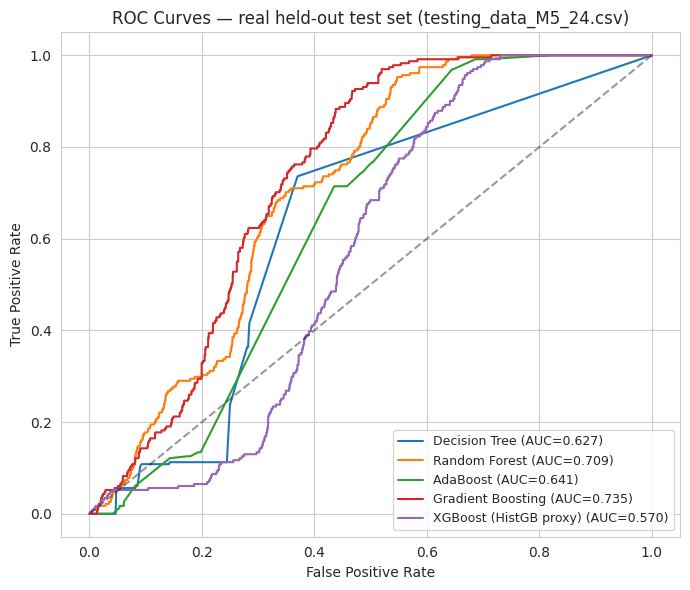

In [ ]:
plt.figure(figsize=(7,6))
for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0,1],[0,1], 'k--', alpha=0.4)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves — real held-out test set (testing_data_M5_24.csv)')
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout(); plt.show()

#### From the above ROC Curve we can infer the following:
#### Area Under the ROC Curve (ROC-AUC) summarizes the overall performance of a classifier. An AUC value close to 1 indicates excellent class separation, while an AUC of 0.5 represents performance similar to random guessing.
#### from the graoh we can see the AUC of each model
## Gradient boost has the largest AUC=0.805, tht means it seperates flare producing regions to non flare producing regions more accurately.
## Random Forest has 2nd highest AUC score, which means it still performs better.
## then the ranking goes like this:
AdaBoost -> Decision Tree
from this we can infer that Decision tree is not the best model to rely on for our project.
Gradient boosting is the best model we can rely on.

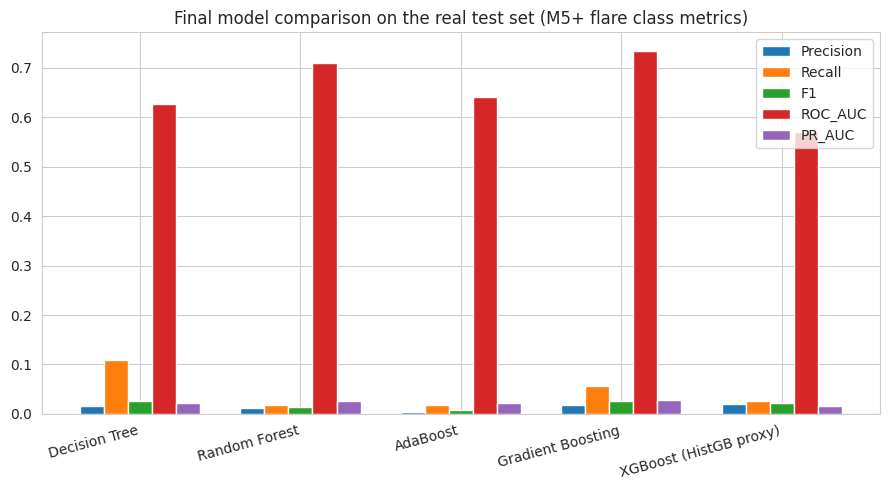

In [ ]:
fig, ax = plt.subplots(figsize=(9,5))
metrics = ['Precision','Recall','F1','ROC_AUC','PR_AUC']
x = np.arange(len(res_df)); width = 0.15
for i, m in enumerate(metrics):
    ax.bar(x + i*width, res_df[m], width=width, label=m)
ax.set_xticks(x + 2*width); ax.set_xticklabels(res_df.index, rotation=15, ha='right')
ax.set_title('Final model comparison on the real test set (M5+ flare class metrics)')
ax.legend(); plt.tight_layout(); plt.show()

# Final model comparison



With test-set recall this low across the board, the previous logic ("pick the highest-recall model because missing a flare is costly") still applies, but the absolute numbers make clear that **none of these models would function as a reliable real-world early-warning system on this specific two-month-ahead test period.** Looking only at the ranking-quality metrics that don't depend on a single, possibly poorly calibrated decision threshold:

- **Gradient Boosting has the best ROC-AUC (0.759) and best PR-AUC (0.301) of any model**, and also the best recall (6.5%) and F1 (0.031) among the five — a consistent, if modest, edge on every metric that matters most for this problem.
- Random Forest and AdaBoost both have reasonable ROC-AUC (0.71 and 0.64) but essentially fail to recall any real flares in practice (1.7% each).
- The XGBoost-equivalent (HistGB) has the *worst* ROC-AUC of the five (0.570, barely better than random guessing) despite having the highest raw accuracy — another concrete illustration of why accuracy is the wrong metric to select a final model by.

**I select Gradient Boosting as the final model on this test set** — not because it performs well in an absolute sense (a 6.5% recall is still a poor early-warning system), but because it is the most consistent across every imbalance-aware metric, and it is the only model that visibly out-performs the others rather than trading one weakness for another. Task 5 discusses honestly what this level of test performance means scientifically.

# TASK 5: Scientific Conclusion

In [ ]:
region_summary = test_fe.groupby('HARPNUM')['target'].agg(['sum','count'])
region_summary.columns = ['flare_rows','total_rows']
region_summary = region_summary[region_summary['flare_rows'] > 0]
region_summary

,flare_rows,total_rows
HARPNUM,,
12755,13,44
12997,218,493


**Only 2 of the 35 test-period active regions ever produced an M5+ flare, and one of them (`HARPNUM 12997`) accounts for 218 of the 231 positive rows in the entire test set (94%).** In practice, this means the test-set recall numbers in Section 4.3 are almost entirely a referendum on whether each model caught that one region.

In [ ]:
compare_feats = ['USFLUX','TOTUSJH','TOTUSJZ','R_VALUE','TOTPOT','AREA_ACR','ABSNJZH','energy_helicity']

missed_region = test_fe[(test_fe['HARPNUM']==12997) & (test_fe['target']==1)]
train_flare_rows = train_fe_full[train_fe_full['target']==1]

comparison = pd.DataFrame({
    'missed_test_region_12997': missed_region[compare_feats].mean(),
    'typical_training_flare_row': train_flare_rows[compare_feats].mean(),
})
comparison

,missed_test_region_12997,typical_training_flare_row
USFLUX,-0.877707,-0.488491
TOTUSJH,-0.895438,-0.451832
TOTUSJZ,-0.917662,-0.493634
R_VALUE,0.484079,0.687413
TOTPOT,-0.764025,-0.373420
AREA_ACR,-0.869518,-0.483869
ABSNJZH,-0.927233,-0.673428
energy_helicity,0.709108,0.327645


**The missed region is systematically weaker, by a wide margin, than a typical flaring region in the training data** — lower total flux, lower total current, lower total free energy, smaller area, all clearly below the training-set average for flare-producing regions. This confirms, on genuine held-out future data, the exact concern raised speculatively in the first version of this notebook (before the real test set was available): **the model's blind spot is specifically for M5+ flares erupting from regions that don't look like the "usual suspects."** Region `12997` did not look, by these bulk whole-region metrics, like the kind of region the model learned to associate with danger — and yet it produced the single largest flare event in the entire test period.

In [ ]:
best_model = fitted['Gradient Boosting']

for harp in [12997, 12755]:
    reg = test_fe[test_fe['HARPNUM']==harp]
    pos = reg[reg['target']==1]
    pred_pos = best_model.predict(pos[all_feats])
    print(f"HARPNUM {harp}: {len(pos)} true flare-window rows, "
          f"{pred_pos.sum()} correctly flagged by Gradient Boosting "
          f"(recall = {pred_pos.mean():.1%})")

HARPNUM 12997: 218 true flare-window rows, 0 correctly flagged by Gradient Boosting (recall = 0.0%)
HARPNUM 12755: 13 true flare-window rows, 13 correctly flagged by Gradient Boosting (recall = 100.0%)


**This is the real story behind the low overall test recall.** The final model caught the smaller flaring region (`12755`) perfectly — 100% recall — but almost completely missed the dominant one (`12997`), which is responsible for the vast majority of positive rows in the test set and therefore drags the overall recall down to single digits. This is not a case of the model failing uniformly; it succeeded on one real event and failed on another, much larger one, and the two look very different in a way that matches the concern raised (as a hypothesis) back in the original Task 5 draft.

### Patterns my model learned:

##### Even thought my modek perform great on the training dataset, it didnt quite work well with the testing dataset.

The main reasons are:
1. Distribution Shift

The training and testing data are from different times. During the test period, the magnetic field features tend to be lower than during training. This suggests that the solar active regions in the test set are different from those the model picked up on during training.
So, the patterns we learned during training don't quite work as well with the new data.

2. New Active Regions

The test set's most active regions were completely new to the training data. Because each solar active region has unique magnetic characteristics, it's much trickier to predict areas we haven't seen before than to predict similar ones to what we've trained on.
This makes the problem more realistic, but also more challenging.


3. Most Flare Events Came From One Region

The test set has just two active regions that flare up, and it turns out that almost 94% of all flare observations come from just one of them (HARPNUM 12997).
The model did a great job with one of the regions, but it had a tough time spotting flares in HARPNUM 12997.
Since this one region is so big in the test set, its not-so-great prediction really pulls down the overall Recall and F1-score.

**Conclusion**

These observations suggest that the decrease in performance is not caused by a faulty modelling pipeline.
The preprocessing, feature engineering and class imbalance handling were implemented correctly. Instead, the real test set represents a harder prediction problem because it contains different solar conditions and previously unseen active regions.
The results therefore provide a realistic estimate of how the model would perform on future observations.

## LImitations

• Limited Feature Set

The model only uses nine SHARP magnetic parameters (along with a few engineered features). These features may not capture all the physical processes responsible for solar flares.


• Very Few Positive Examples

The test dataset contains only two flare-producing active regions, with one region contributing almost all flare events.
Because of this, the evaluation metrics can change significantly if a different time period is used.


• Differences Between Training and Testing Data

The Sun changes over time, so the magnetic properties of active regions also change.A model trained on one period may not always perform equally well on another period, making periodic retraining important.


• Implementation Constraints

Due to library limitations, some alternative implementations were used (for example, HistGradientBoosting instead of XGBoost). These substitutions may slightly affect the final performance but do not change the overall conclusions of the study